---
# Cuaderno 1: Analysis of TCGA database
---
Author: Melissa Ormeño

Laboratory: Cancer Molecular Dynamics

Date: Mayo 2026



In [1]:
import gzip
import io
import json
import pandas as pd
import requests
import matplotlib.pyplot as plt
import numpy as np

## Extracting mutations from the TCGA (MAF file)

In [11]:
import json
import requests
import numpy as np
import pandas as pd

# Define target gene panels for the TGF-beta pathway
gen_list = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1', 'TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

# Map GDC TCGA project identifiers to primary tumor sites
projects_gdc = {
    "TCGA-BRCA": "Breast",
    "TCGA-LUAD": "Bronchus and lung",
    "TCGA-LUSC": "Bronchus and lung",
    "TCGA-KIRC": "Kidney",
    "TCGA-KIRP": "Kidney",
    "TCGA-BLCA": "Bladder",
    "TCGA-COAD": "Colon",
    "TCGA-READ": "Rectum",
    "TCGA-STAD": "Stomach",
    "TCGA-LGG":  "Brain",
    "TCGA-GBM":  "Brain",
    "TCGA-UCEC": "Uterus",
    "TCGA-UCS":  "Uterus",
    "TCGA-OV":   "Ovary",
    "TCGA-LIHC": "Liver and intrahepatic bile ducts",
    "TCGA-PAAD": "Pancreas",
    "TCGA-ESCA": "Esophagus",
    "TCGA-THCA": "Thyroid gland",
    "TCGA-SKCM": "Skin"
}

ssm_endpt = "https://api.gdc.cancer.gov/ssms"
mut_list = []

print(f"Launching a query in the TCGA database: {len(projects_gdc)} projects and {len(gen_list)} genes")

for idx, project in enumerate(projects_gdc, 1):
    # Construct GDC API relational payload filters
    filters = {
        "op": "and",
        "content": [
            {"op": "in", "content": {"field": "consequence.transcript.gene.symbol", "value": gen_list}},
            {"op": "in", "content": {"field": "occurrence.case.project.project_id", "value": [project]}},
        ],
    }

    fields = [
        "ssm_id",
        "chromosome",
        "genomic_dna_change",  
        "mutation_subtype",  
        "ncbi_build",
        "reference_allele",  
        "tumor_allele",  
        "consequence.transcript.gene.symbol",
        "consequence.transcript.aa_change",  
        "consequence.transcript.hgvsp",  
        "consequence.transcript.annotation.vep_impact",
        "consequence.transcript.consequence_type",  
        "occurrence.case.submitter_id",  
        "occurrence.case.project.project_id",
    ]

    params = {
        "filters": json.dumps(filters),
        "fields": ",".join(fields),
        "format": "JSON",
        "size": "2000",  
    }

    try:
        response = requests.get(ssm_endpt, params=params)
        data = response.json()
        hits = data.get("data", {}).get("hits", [])
    except Exception as e:
        print(f"    Error connecting to the project {project}: {e}")
        continue

    if not hits:
        continue

    for hit in hits:
        # FIX: Iterate through transcripts to isolate the correct target gene from gen_list
        consequences = hit.get("consequence", [])
        target_consequence = None
        
        for cons in consequences:
            trans_info = cons.get("transcript", {})
            sym = trans_info.get("gene", {}).get("symbol")
            if sym in gen_list:
                target_consequence = cons
                break
        
        # Fallback to the first transcript block if no exact match is isolated
        if not target_consequence and consequences:
            target_consequence = consequences[0]
        elif not consequences:
            continue

        transcript_info = target_consequence.get("transcript", {})
        gene_symbol = transcript_info.get("gene", {}).get("symbol", "Unknown")
        aa_change = transcript_info.get("aa_change", "p.?")
        aa_long = transcript_info.get("hgvsp", "p.?")
       
        raw_efect = transcript_info.get("consequence_type", "Unknown")
        efect_maf = raw_efect.replace("_variant", "_Mutation").capitalize()
        
        # Standardize consequence terms to MAF format specifications
        if "missense" in raw_efect:
            efect_maf = "Missense_Mutation"
        elif "synonymous" in raw_efect:
            efect_maf = "Silent"
        elif "stop_gained" in raw_efect:
            efect_maf = "Nonsense_Mutation"
        
        # Map genomic structural events to individual patient cases
        for occ in hit.get("occurrence", []):
            patient_id = occ.get("case", {}).get("submitter_id", "Unknown")
            proj_id = occ.get("case", {}).get("project", {}).get("project_id", project)

            registro = {
                "Patient_ID": patient_id,
                "Tumor_Sample_Barcode": f"{patient_id}-TUMOR", 
                "Hugo_Symbol": gene_symbol,
                "Chromosome": hit.get("chromosome"),
                "Variant_Classification": efect_maf,
                "Variant_Type": hit.get("mutation_subtype"),
                "Reference_Allele": hit.get("reference_allele"),
                "Tumor_Seq_Allele2": hit.get("tumor_allele"),
                "HGVSc": hit.get("genomic_dna_change"),
                "HGVSp_Short": aa_change,
                "HGVSp": aa_long,  
                "Project_ID": proj_id,
            }
            mut_list.append(registro)

# Construct primary output dataframe
maf_genes = pd.DataFrame(mut_list)

# Map GDC cohort projects to primary anatomical tumor sites
maf_genes["cancer_type"] = maf_genes["Project_ID"].map(projects_gdc)

# Filter out non-functional silent variants
maf_genes = maf_genes.loc[~(maf_genes["Variant_Classification"] == "Silent")]

# Drop incomplete annotations and missing site values
maf_genes = maf_genes.dropna(subset=["cancer_type", "HGVSp_Short"])
maf_genes["HGVSp_Short"] = maf_genes["HGVSp_Short"].replace("p.?", np.nan)
maf_genes = maf_genes.dropna(subset=["HGVSp_Short"])

print(f"Completed: {maf_genes['Project_ID'].nunique()} mapped projects")

miss_mut = maf_genes[maf_genes["Variant_Classification"]=="Missense_Mutation"]

# Export parsed records to repository storage
file_path = "../data/TCGA/mutaciones_TCGA.csv"
file_path_miss = "../data/TCGA/mut_missense_TCGA.csv"

maf_genes.to_csv(file_path, index=False)
miss_mut.to_csv(file_path_miss, index=False)

print(f"File saved in: {file_path}")
print(f"Patient count: {miss_mut['Patient_ID'].nunique()}")
print(f"Mutation count: {miss_mut['HGVSp_Short'].nunique()}")
print(f"Cancer types ({miss_mut['cancer_type'].nunique()}): {', '.join(miss_mut['cancer_type'].unique())}")
maf_genes

Launching a query in the TCGA database: 19 projects and 12 genes
Completed: 19 mapped projects
File saved in: ../data/TCGA/mutaciones_TCGA.csv
Patient count: 457
Mutation count: 595
Cancer types (15): Breast, Colon, Bladder, Bronchus and lung, Pancreas, Kidney, Ovary, Stomach, Uterus, Skin, Rectum, Brain, Liver and intrahepatic bile ducts, Thyroid gland, Esophagus


,Patient_ID,Tumor_Sample_Barcode,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,cancer_type
0,TCGA-A6-6781,TCGA-A6-6781-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon
1,TCGA-A5-A2K3,TCGA-A5-A2K3-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-UCEC,Uterus
3,TCGA-CG-4306,TCGA-CG-4306-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach
5,TCGA-QG-A5Z2,TCGA-QG-A5Z2-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-COAD,Colon
6,TCGA-VQ-A91E,TCGA-VQ-A91E-TUMOR,ACVR2A,chr2,Frameshift_mutation,Small deletion,A,-,chr2:g.147926117delA,K437Rfs*5,p.?,TCGA-STAD,Stomach
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4052,TCGA-FW-A3R5,TCGA-FW-A3R5-TUMOR,ACVR1C,chr2,Missense_Mutation,Single base substitution,G,A,chr2:g.157538649G>A,S270L,p.?,TCGA-SKCM,Skin
4056,TCGA-W3-AA1V,TCGA-W3-AA1V-TUMOR,BMPR1A,chr10,Missense_Mutation,Single base substitution,G,A,chr10:g.86912317G>A,G203E,p.?,TCGA-SKCM,Skin
4060,TCGA-ER-A193,TCGA-ER-A193-TUMOR,BMPR1A,chr10,Nonsense_Mutation,Single base substitution,C,T,chr10:g.86923702C>T,Q528*,p.?,TCGA-SKCM,Skin
4061,TCGA-D3-A1Q4,TCGA-D3-A1Q4-TUMOR,AMHR2,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.53425181G>A,M147I,p.?,TCGA-SKCM,Skin


## Graphs

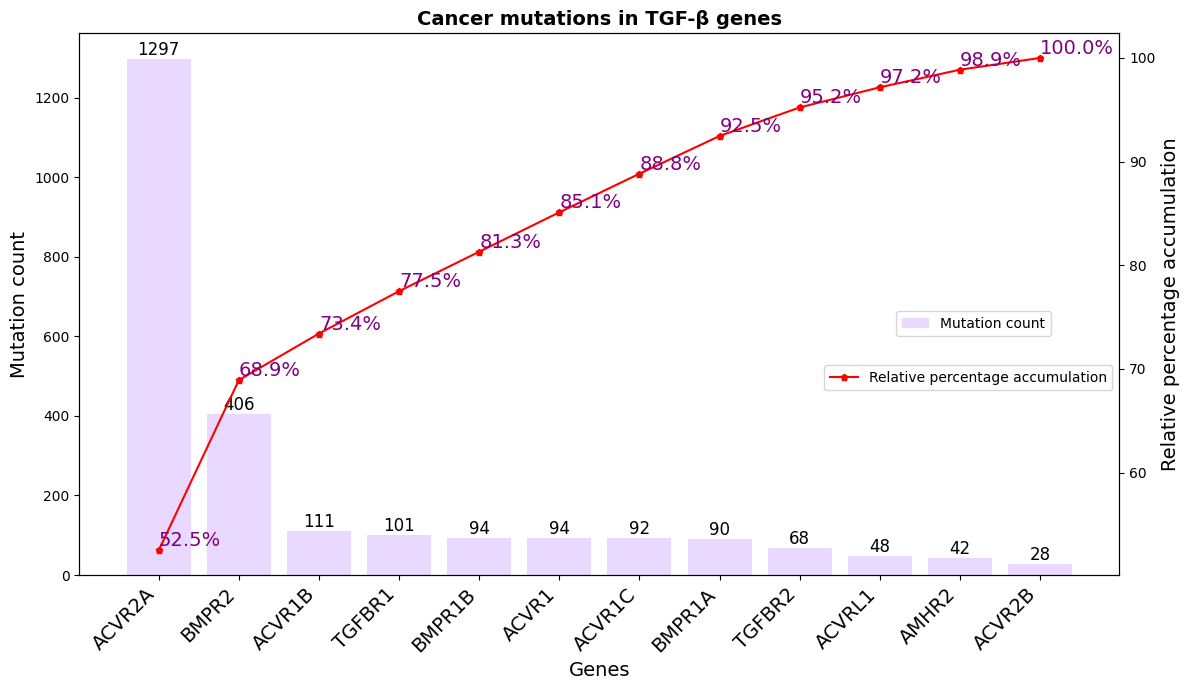

In [7]:
#GENERAL PARAMETERS
df = maf_genes 
count = "HGVSp_Short" 
grupo = "Hugo_Symbol" 
mutation_counts = df.groupby(grupo, as_index=False)[count].count() 

#LABEL PARAMETERS
ylabel = 'Mutation count' # label axis y
ylabel2 = 'Relative percentage accumulation' # label axis y2
set_title = 'Cancer mutations in TGF-β genes' # title
set_xlabel = 'Genes' # title axis X
leyenda_2 = 'Relative percentage accumulation' # label axis 2
leyenda_count = 'Mutation count' # label axis 1

#COLORS PARAMETERS
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

# SAVED
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # or svg
DPI = 600 
NOMBRE_IMAGEN = "CancerMut_gene_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"

# Sort from highest to lowest
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calculate the cumulative percentage
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# shape and axes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

#  Bar chart mutation count
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# line cumulative percentage
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Add labels with the number of mutations above the bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Add labels showing the cumulative percentage at points along the line
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)

# labels
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# label axis x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# add label 
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  

plt.tight_layout()

# save graph
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()

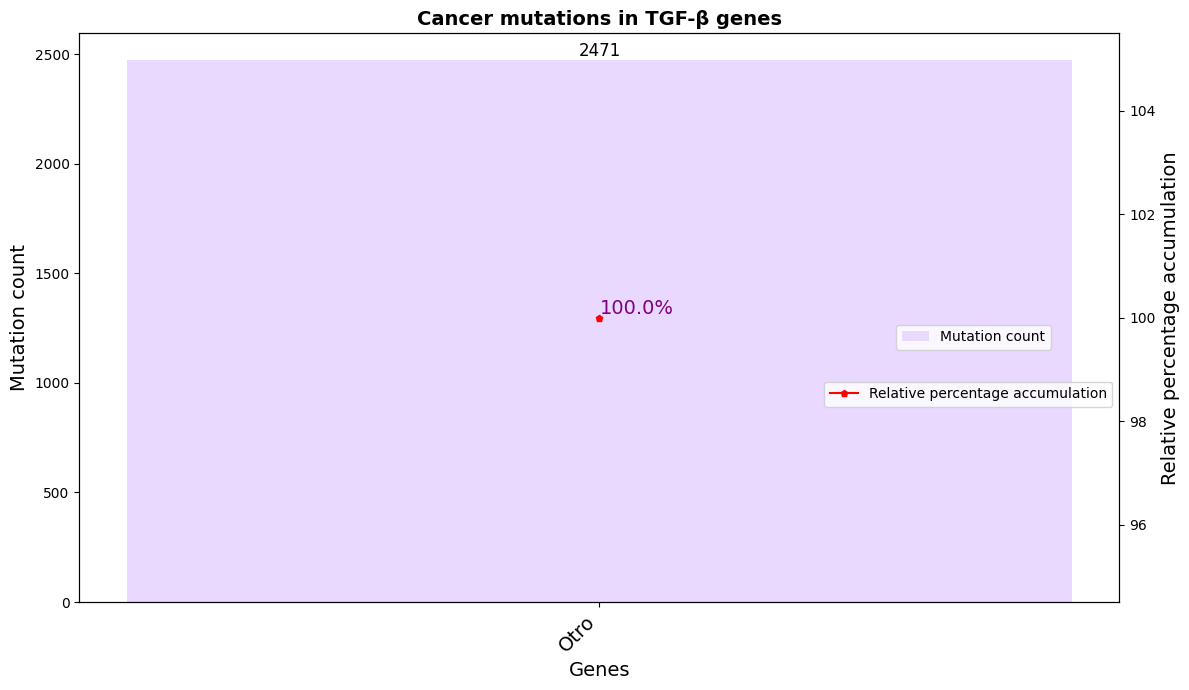

In [16]:
#GENERAL PARAMETERS
df = maf_genes 
count = "HGVSp_Short" 
grupo = "Dominio" 
mutation_counts = df.groupby(grupo, as_index=False)[count].count() 

#LABEL PARAMETERS
ylabel = 'Mutation count' # label axis y
ylabel2 = 'Relative percentage accumulation' # label axis y2
set_title = 'Cancer mutations in TGF-β genes' # title
set_xlabel = 'Genes' # title axis X
leyenda_2 = 'Relative percentage accumulation' # label axis 2
leyenda_count = 'Mutation count' # label axis 1

#COLORS PARAMETERS
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

# SAVED
GUARDAR_GRAFICO = False
FORMATO_IMAGEN = "png"  # or svg
DPI = 600 
NOMBRE_IMAGEN = "CancerMut_gene_tgfb"
RUTA = f"../run/imagenes/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"

# Sort from highest to lowest
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calculate the cumulative percentage
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# shape and axes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

#  Bar chart mutation count
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# line cumulative percentage
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Add labels with the number of mutations above the bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Add labels showing the cumulative percentage at points along the line
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)

# labels
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# label axis x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# add label 
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  

plt.tight_layout()

# save graph
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()

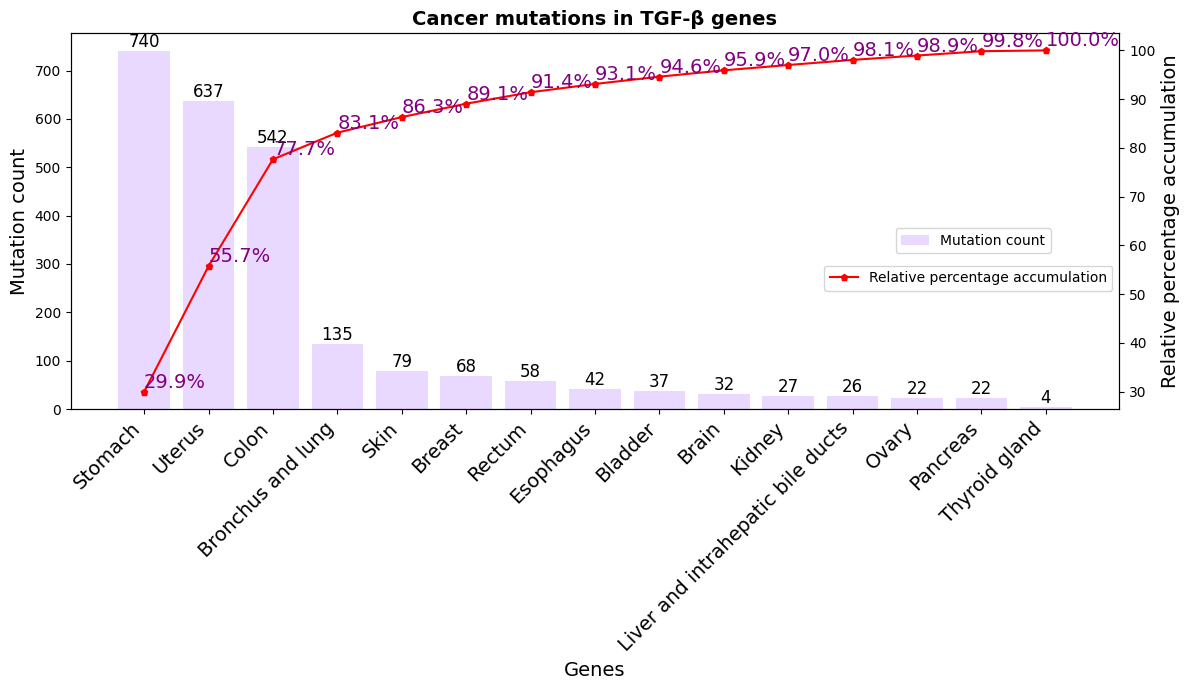

In [26]:
#GENERAL PARAMETERS
df = maf_genes 
count = "HGVSp_Short" 
grupo = "cancer_type" 
mutation_counts = df.groupby(grupo, as_index=False)[count].count() 

#LABEL PARAMETERS
ylabel = 'Mutation count' # label axis y
ylabel2 = 'Relative percentage accumulation' # label axis y2
set_title = 'Cancer mutations in TGF-β genes' # title
set_xlabel = 'Genes' # title axis X
leyenda_2 = 'Relative percentage accumulation' # label axis 2
leyenda_count = 'Mutation count' # label axis 1

#COLORS PARAMETERS
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

# SAVED
GUARDAR_GRAFICO = True
FORMATO_IMAGEN = "png"  # or svg
DPI = 600 
NOMBRE_IMAGEN = "CancerMut_gene_tgfb"
RUTA = f"../pictures/{NOMBRE_IMAGEN}_.{FORMATO_IMAGEN}"

# Sort from highest to lowest
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Calculate the cumulative percentage
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# shape and axes
fig, ax = plt.subplots(figsize=(12, 7))  # Ajusta el tamaño de la figura

#  Bar chart mutation count
bars = ax.bar(mutation_counts[grupo], mutation_counts[count])
ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# line cumulative percentage
ax2 = ax.twinx()
ax2.plot(mutation_counts.index, mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Add labels with the number of mutations above the bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom', color='black', fontsize=12)

# Add labels showing the cumulative percentage at points along the line
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(i, value, f'{value:.1f}%', ha='left', va='bottom', color=numero_acumulacion, fontsize=14)

# labels
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight = "bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# label axis x
ax.set_xticks(range(len(mutation_counts[grupo])))  # Colocar las etiquetas en las posiciones correctas
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)  # Rotar las etiquetas y alinearlas a la derecha

# add label 
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))  
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))  

plt.tight_layout()

# save graph
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI)
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN)

plt.show()

In [9]:
mut_missense = maf_genes[maf_genes["Variant_Classification"]=="Missense_Mutation"]
mut_missense

,Patient_ID,Tumor_Sample_Barcode,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,cancer_type
197,TCGA-BH-A0HF,TCGA-BH-A0HF-TUMOR,ACVR2A,chr2,Missense_Mutation,Single base substitution,C,T,chr2:g.147915234C>T,P83L,p.?,TCGA-BRCA,Breast
205,TCGA-E9-A2JT,TCGA-E9-A2JT-TUMOR,ACVRL1,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.51914483G>A,E50K,p.?,TCGA-BRCA,Breast
206,TCGA-BH-A1F2,TCGA-BH-A1F2-TUMOR,ACVR2A,chr2,Missense_Mutation,Single base substitution,A,T,chr2:g.147918475A>T,N282I,p.?,TCGA-BRCA,Breast
208,TCGA-G4-6625,TCGA-G4-6625-TUMOR,TGFBR1,chr9,Missense_Mutation,Single base substitution,G,A,chr9:g.99128996G>A,R80Q,p.?,TCGA-COAD,Colon
209,TCGA-AR-A2LE,TCGA-AR-A2LE-TUMOR,TGFBR1,chr9,Missense_Mutation,Single base substitution,G,A,chr9:g.99128996G>A,R80Q,p.?,TCGA-BRCA,Breast
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4047,TCGA-EE-A2GI,TCGA-EE-A2GI-TUMOR,ACVR1C,chr2,Missense_Mutation,Single base substitution,G,A,chr2:g.157587306G>A,S62F,p.?,TCGA-SKCM,Skin
4048,TCGA-EE-A183,TCGA-EE-A183-TUMOR,ACVR1C,chr2,Missense_Mutation,Single base substitution,C,T,chr2:g.157541152C>T,R308Q,p.?,TCGA-SKCM,Skin
4052,TCGA-FW-A3R5,TCGA-FW-A3R5-TUMOR,ACVR1C,chr2,Missense_Mutation,Single base substitution,G,A,chr2:g.157538649G>A,S270L,p.?,TCGA-SKCM,Skin
4056,TCGA-W3-AA1V,TCGA-W3-AA1V-TUMOR,BMPR1A,chr10,Missense_Mutation,Single base substitution,G,A,chr10:g.86912317G>A,G203E,p.?,TCGA-SKCM,Skin


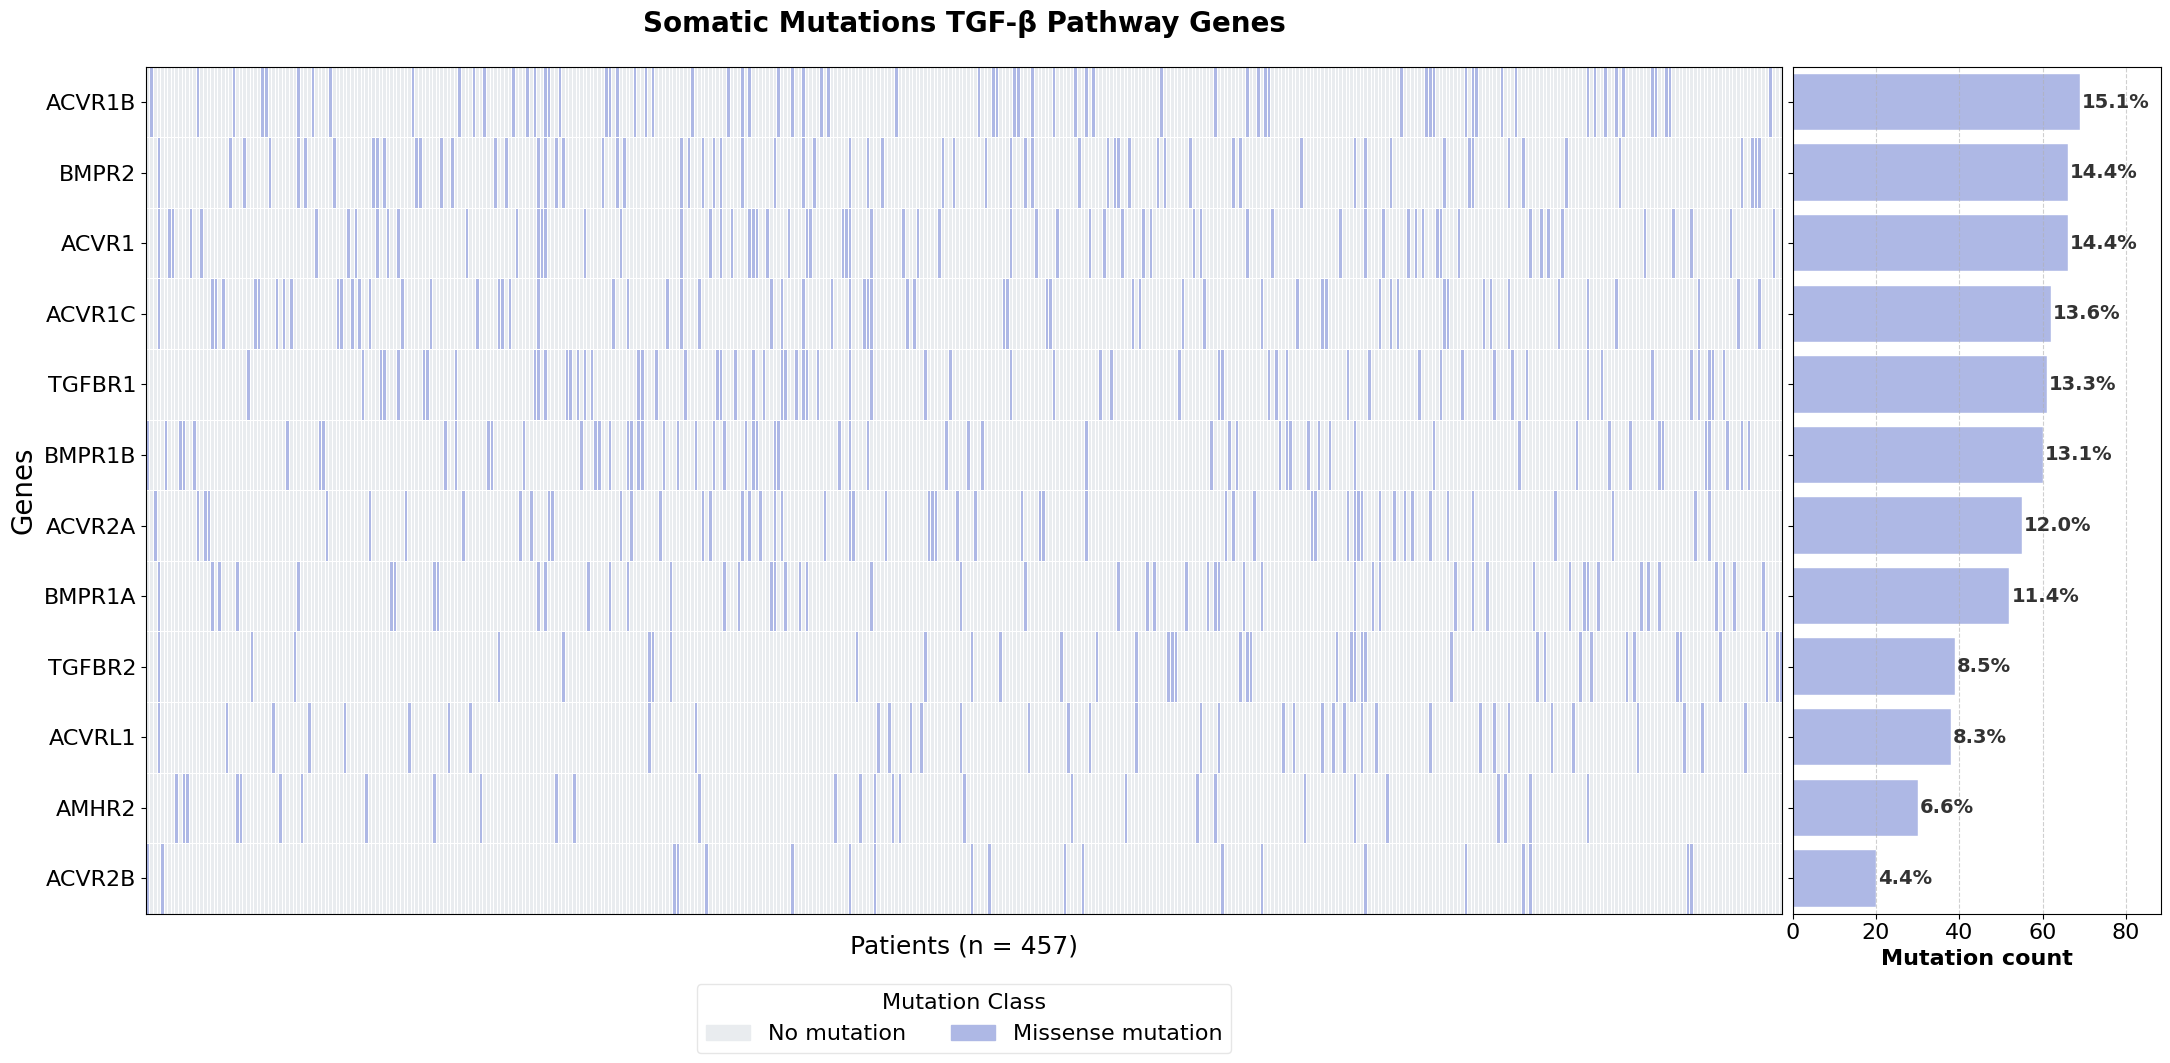

In [24]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

# Define color palette for mutation classes
color_dict = {
    "No mutation":        {"val": 0, "color": "#e9ecef"},
    "Missense_Mutation":  {"val": 1, "color": "#AEB8E5"},
}

# Subselect critical genomic coordinates and compute variant occurrences
mut_df = miss_mut[["Patient_ID", "Hugo_Symbol", "Variant_Classification", "HGVSp_Short"]]
mut_df = mut_df.groupby(["Patient_ID", "Hugo_Symbol", "Variant_Classification"])["HGVSp_Short"].count().reset_index()

# Drop rows with missing critical annotations
df_maf = mut_df.dropna(subset=['Hugo_Symbol', 'Patient_ID', 'Variant_Classification']).copy()

# Sort genes by mutation frequency
gene_counts = df_maf['Hugo_Symbol'].value_counts().sort_values(ascending=True)
genes_ordenados = gene_counts.index.tolist()

# Construct the mutation matrix
df_matrix = df_maf.pivot_table(
    index='Hugo_Symbol', 
    columns='Patient_ID', 
    values='Variant_Classification',
    aggfunc=lambda x: x.iloc[0]
).fillna("No mutation")

# Map categorical classifications to numerical values with a safe default fallback
df_matrix_num = df_matrix.map(lambda x: color_dict.get(x, color_dict["No mutation"])["val"])
df_matrix_num = df_matrix_num.reindex(genes_ordenados)

# Sort patients hierarchically to generate the characteristic cascade pattern
pacientes_ordenados = df_matrix_num.T.index
df_matrix_num = df_matrix_num[pacientes_ordenados]

num_total_pacientes = df_matrix_num.shape[1]

# Generate the categorical colormap
colores_lista = [c["color"] for c in sorted(color_dict.values(), key=lambda x: x["val"])]
cmap_onco = ListedColormap(colores_lista)

# Initialize plot subplots
fig, (ax_main, ax_right) = plt.subplots(
    1, 2, 
    figsize=(26, 11), 
    gridspec_kw={'width_ratios': [4, 0.9]}, 
    sharey=True
)
fig.subplots_adjust(wspace=0.01)

# Plot primary mutation matrix using a specialized discrete mesh grid
ax_main.pcolormesh(
    df_matrix_num.values, 
    cmap=cmap_onco, 
    edgecolors='white', 
    linewidths=0.4, 
    vmin=0, 
    vmax=len(colores_lista)-1
)

ax_main.set_title("Somatic Mutations TGF-β Pathway Genes", fontsize=20, pad=25, weight='bold')
ax_main.set_xticks([]) 
ax_main.set_xlabel(f"Patients (n = {num_total_pacientes})", fontsize=18, labelpad=15)
ax_main.set_ylabel("Genes", fontsize=20)
ax_main.set_yticks(np.arange(df_matrix_num.shape[0]) + 0.5)
ax_main.set_yticklabels(df_matrix_num.index, fontsize=16)

# Calculate and plot stacked mutation frequencies
y_positions = np.arange(len(genes_ordenados)) + 0.5
left_acumulado = np.zeros(len(genes_ordenados))

for val_num in range(1, len(colores_lista)):
    color_actual = colores_lista[val_num]
    conteos_por_gen = (df_matrix_num == val_num).sum(axis=1).values
    
    ax_right.barh(
        y_positions, 
        conteos_por_gen, 
        left=left_acumulado, 
        color=color_actual, 
        edgecolor='white',   
        linewidth=0.3,
        height=0.8
    )
    left_acumulado += conteos_por_gen

# Calculate absolute counts and cohort percentages for annotations
conteos_totales_gen = (df_matrix_num > 0).sum(axis=1).values
frecuencia_total_gen = (conteos_totales_gen / num_total_pacientes) * 100

# Annotate cohort penetrancy percentages alongside absolute bars
for i, count in enumerate(conteos_totales_gen):
    pct = frecuencia_total_gen[i]
    ax_right.text(
        count + 0.5, 
        y_positions[i], 
        f"{pct:.1f}%", 
        va='center', 
        ha='left', 
        fontsize=14, 
        weight='bold',
        color='#333333'
    )

# Format side bar chart axes using discrete absolute counts
ax_right.grid(axis='x', linestyle='--', alpha=0.6, zorder=0)
ax_right.set_xlabel("Mutation count", fontsize=16, weight='bold')
ax_right.set_xlim(0, max(conteos_totales_gen) * 1.28) 
ax_right.set_yticks(y_positions)
ax_right.tick_params(axis='x', which='both', labelsize=16)

# Synchronize subplot vertical boundaries
ax_main.set_ylim(0, df_matrix_num.shape[0])
ax_right.set_ylim(0, df_matrix_num.shape[0])

# Construct and position the mutation class legend
leyenda_parches = []
nombres_vistos = set()
for name, info in color_dict.items():
    clean_name = name.replace("_", " ").capitalize()
    if info["val"] not in nombres_vistos:
        leyenda_parches.append(mpatches.Patch(color=info["color"], label=clean_name))
        nombres_vistos.add(info["val"])

ax_main.legend(
    handles=leyenda_parches, 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.07), 
    ncol=4, 
    title="Mutation Class", 
    title_fontsize=16,
    fontsize=16, 
    frameon=True,
    facecolor='white',
    edgecolor='#e0e0e0'
)

# Export publication-ready graphics vectors
plt.savefig("../pictures/oncoplot_mut_cancer.png", dpi=600, bbox_inches='tight')
plt.savefig("../pictures/oncoplot_mut_cancer.svg", bbox_inches='tight')
plt.show()

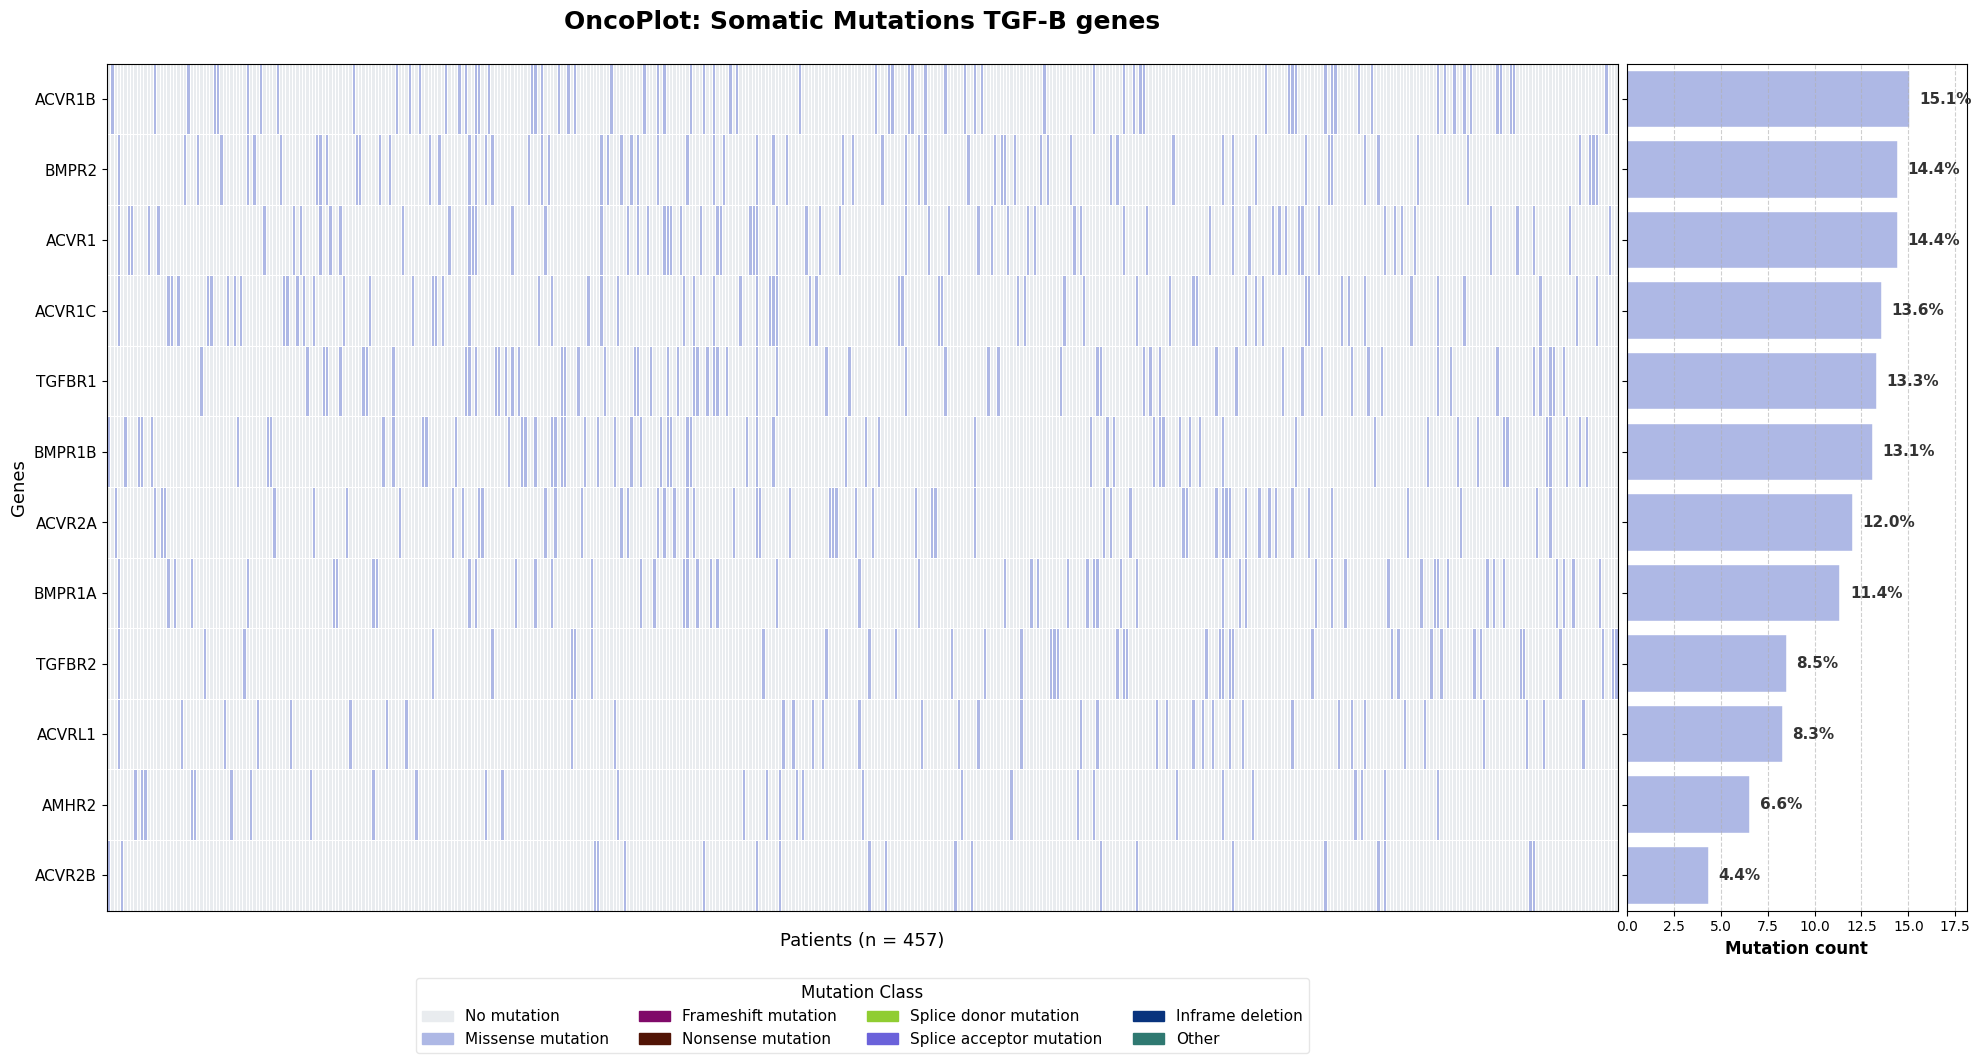

In [11]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

# Define color palette for mutation classes
color_dict = {
    "No mutation":               {"val": 0, "color": "#e9ecef"},
    "Missense_Mutation":         {"val": 1, "color": "#AEB8E5"},
    "Frameshift_mutation":       {"val": 2, "color": "#800A69"},
    "Nonsense_Mutation":         {"val": 3, "color": "#511405"},
    "Splice_donor_mutation":     {"val": 4, "color": "#90CD32"},
    "Splice_acceptor_mutation":  {"val": 5, "color": "#6B62DA"},
    "Inframe_deletion":          {"val": 6, "color": "#08337D"},
    "Other":                     {"val": 7, "color": "#2F7971"},
}

mut_df = mut_missense[["Patient_ID","Hugo_Symbol","Variant_Classification","HGVSp_Short"]]
mut_df = mut_df.groupby(["Patient_ID","Hugo_Symbol","Variant_Classification"])["HGVSp_Short"].count().reset_index()

# Drop rows with missing critical annotations
df_maf = mut_df.dropna(subset=['Hugo_Symbol', 'Patient_ID', 'Variant_Classification']).copy()

# Sort genes by mutation frequency
gene_counts = df_maf['Hugo_Symbol'].value_counts().sort_values(ascending=True)
genes_ordenados = gene_counts.index.tolist()

# Construct the mutation matrix
df_matrix = df_maf.pivot_table(
    index='Hugo_Symbol', 
    columns='Patient_ID', 
    values='Variant_Classification',
    aggfunc=lambda x: x.iloc[0]
).fillna("No mutation")

# Map categorical classifications to numerical values
df_matrix_num = df_matrix.map(lambda x: color_dict.get(x, color_dict["Other"])["val"])
df_matrix_num = df_matrix_num.reindex(genes_ordenados)

# Sort patients to generate the cascade pattern
pacientes_ordenados = df_matrix_num.T.index
df_matrix_num = df_matrix_num[pacientes_ordenados]

num_total_pacientes = df_matrix_num.shape[1]

# Generate the colormap
colores_lista = [c["color"] for c in sorted(color_dict.values(), key=lambda x: x["val"])]
cmap_onco = ListedColormap(colores_lista)

# Initialize plot subplots
fig, (ax_main, ax_right) = plt.subplots(
    1, 2, 
    figsize=(24, 11), 
    gridspec_kw={'width_ratios': [4, 0.9]}, 
    sharey=True
)
fig.subplots_adjust(wspace=0.01)

# Plot primary mutation matrix
ax_main.pcolormesh(
    df_matrix_num.values, 
    cmap=cmap_onco, 
    edgecolors='white', 
    linewidths=0.4, 
    vmin=0, 
    vmax=len(colores_lista)-1
)

ax_main.set_title("OncoPlot: Somatic Mutations TGF-B genes", fontsize=18, pad=25, weight='bold')
ax_main.set_xticks([]) 
ax_main.set_xlabel(f"Patients (n = {num_total_pacientes})", fontsize=13, labelpad=15)
ax_main.set_ylabel("Genes", fontsize=13)
ax_main.set_yticks(np.arange(df_matrix_num.shape[0]) + 0.5)
ax_main.set_yticklabels(df_matrix_num.index, fontsize=11)

# Calculate and plot stacked mutation frequencies (%)
y_positions = np.arange(len(genes_ordenados)) + 0.5
left_acumulado = np.zeros(len(genes_ordenados))

for val_num in range(1, len(colores_lista)):
    color_actual = colores_lista[val_num]
    conteos_absolutos = (df_matrix_num == val_num).sum(axis=1).values
    porcentajes = (conteos_absolutos / num_total_pacientes) * 100
    
    ax_right.barh(
        y_positions, 
        porcentajes, 
        left=left_acumulado, 
        color=color_actual, 
        edgecolor='white',   
        linewidth=0.3,
        height=0.8
    )
    left_acumulado += porcentajes

# Annotate total frequency percentages next to bars
frecuencia_total_gen = ((df_matrix_num > 0).sum(axis=1).values / num_total_pacientes) * 100

for i, pct in enumerate(frecuencia_total_gen):
    ax_right.text(
        pct + 0.5, 
        y_positions[i], 
        f"{pct:.1f}%", 
        va='center', 
        ha='left', 
        fontsize=11, 
        weight='bold',
        color='#333333'
    )

# Format frequency axis
ax_right.grid(axis='x', linestyle='--', alpha=0.6, zorder=0)
ax_right.set_xlabel("Mutation count", fontsize=12, weight='bold')
ax_right.set_xlim(0, max(frecuencia_total_gen) * 1.2) 
ax_right.set_yticks(y_positions)

# Synchronize panel boundaries
ax_main.set_ylim(0, df_matrix_num.shape[0])
ax_right.set_ylim(0, df_matrix_num.shape[0])

# Construct and position the legend
leyenda_parches = []
nombres_vistos = set()
for name, info in color_dict.items():
    clean_name = name.replace("_", " ").capitalize()
    if info["val"] not in nombres_vistos:
        leyenda_parches.append(mpatches.Patch(color=info["color"], label=clean_name))
        nombres_vistos.add(info["val"])

ax_main.legend(
    handles=leyenda_parches, 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.07), 
    ncol=4, 
    title="Mutation Class", 
    title_fontsize=12,
    fontsize=11, 
    frameon=True,
    facecolor='white',
    edgecolor='#e0e0e0'
)

plt.show()